# Fraud Detection in Financial Transactions
## Data Engineering Lab - Capstone Project

**Dataset:** Credit Card Fraud Detection (Kaggle)  
**Total Records:** 284,807 transactions  
**Tools:** Python, Pandas, Scikit-learn, SQLite, Matplotlib, Seaborn

## Phase 1: Data Loading & Exploration
Loading the dataset and performing exploratory data analysis (EDA).

In [49]:
import pandas as pd

df = pd.read_csv('creditcard.csv')
print("Loaded!", df.shape)

Loaded! (284807, 31)


In [4]:
print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing Values:\n", df.isnull().sum())

Shape: (284807, 31)

Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Missing Values:
 Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [5]:
print("Class Distribution:")
print(df['Class'].value_counts())
print("\nFraud %:", round(df['Class'].value_counts()[1] / len(df) * 100, 4), "%")

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64

Fraud %: 0.1727 %


In [6]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


## Phase 2: ETL Pipeline
Extract → Transform (cleaning, scaling, deduplication) → Load to warehouse.

In [9]:
# Transform Step
df_clean = df.copy()

# 1. Check for duplicates
print("Duplicates:", df_clean.duplicated().sum())
df_clean = df_clean.drop_duplicates()

# 2. Normalize Amount column (V1-V28 are already scaled)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df_clean['Amount_Scaled'] = scaler.fit_transform(df_clean[['Amount']])
df_clean['Time_Scaled'] = scaler.fit_transform(df_clean[['Time']])

# 3. Drop original Amount and Time
df_clean = df_clean.drop(columns=['Amount', 'Time'])

print("Cleaned shape:", df_clean.shape)
print("Transform complete ✅")

Duplicates: 1081
Cleaned shape: (283726, 31)
Transform complete ✅


In [10]:
# Load Step - save cleaned data
df_clean.to_csv('cleaned_transactions.csv', index=False)
print("Data loaded to warehouse ✅")
print("Cleaned file saved as cleaned_transactions.csv")

Data loaded to warehouse ✅
Cleaned file saved as cleaned_transactions.csv


## Phase 3: Data Visualization & EDA
Visualizing class imbalance, amount distributions and feature correlations.

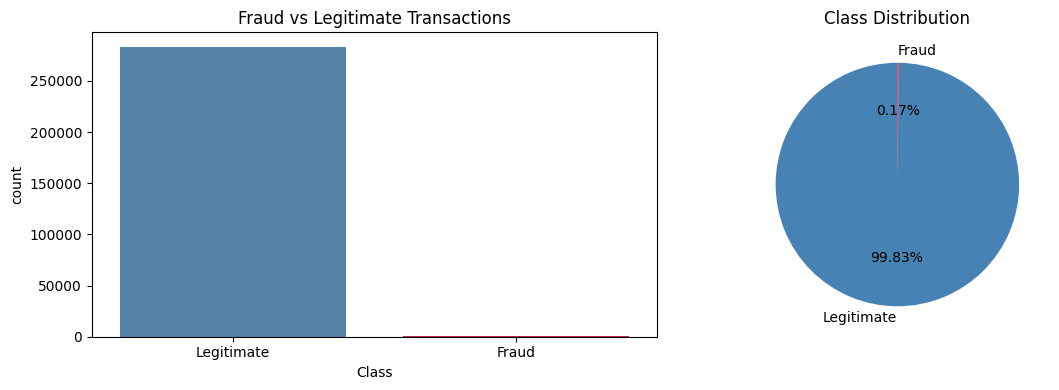

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot (fixed)
sns.countplot(x='Class', data=df_clean, hue='Class',
              palette={0: 'steelblue', 1: 'crimson'}, legend=False, ax=axes[0])
axes[0].set_title('Fraud vs Legitimate Transactions')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Legitimate', 'Fraud'])

# Pie chart
df_clean['Class'].value_counts().plot(kind='pie', ax=axes[1],
    labels=['Legitimate', 'Fraud'], colors=['steelblue', 'crimson'],
    autopct='%1.2f%%', startangle=90)
axes[1].set_title('Class Distribution')
axes[1].set_ylabel('')

plt.tight_layout()
plt.savefig('class_distribution.png')
plt.show()

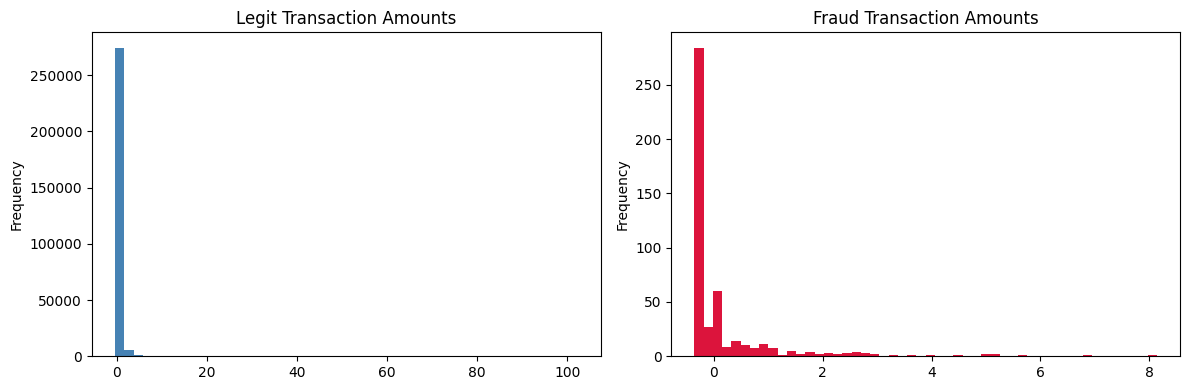

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df_clean[df_clean['Class']==0]['Amount_Scaled'].plot(
    kind='hist', bins=50, ax=axes[0], color='steelblue', title='Legit Transaction Amounts')
df_clean[df_clean['Class']==1]['Amount_Scaled'].plot(
    kind='hist', bins=50, ax=axes[1], color='crimson', title='Fraud Transaction Amounts')

plt.tight_layout()
plt.savefig('amount_distribution.png')
plt.show()

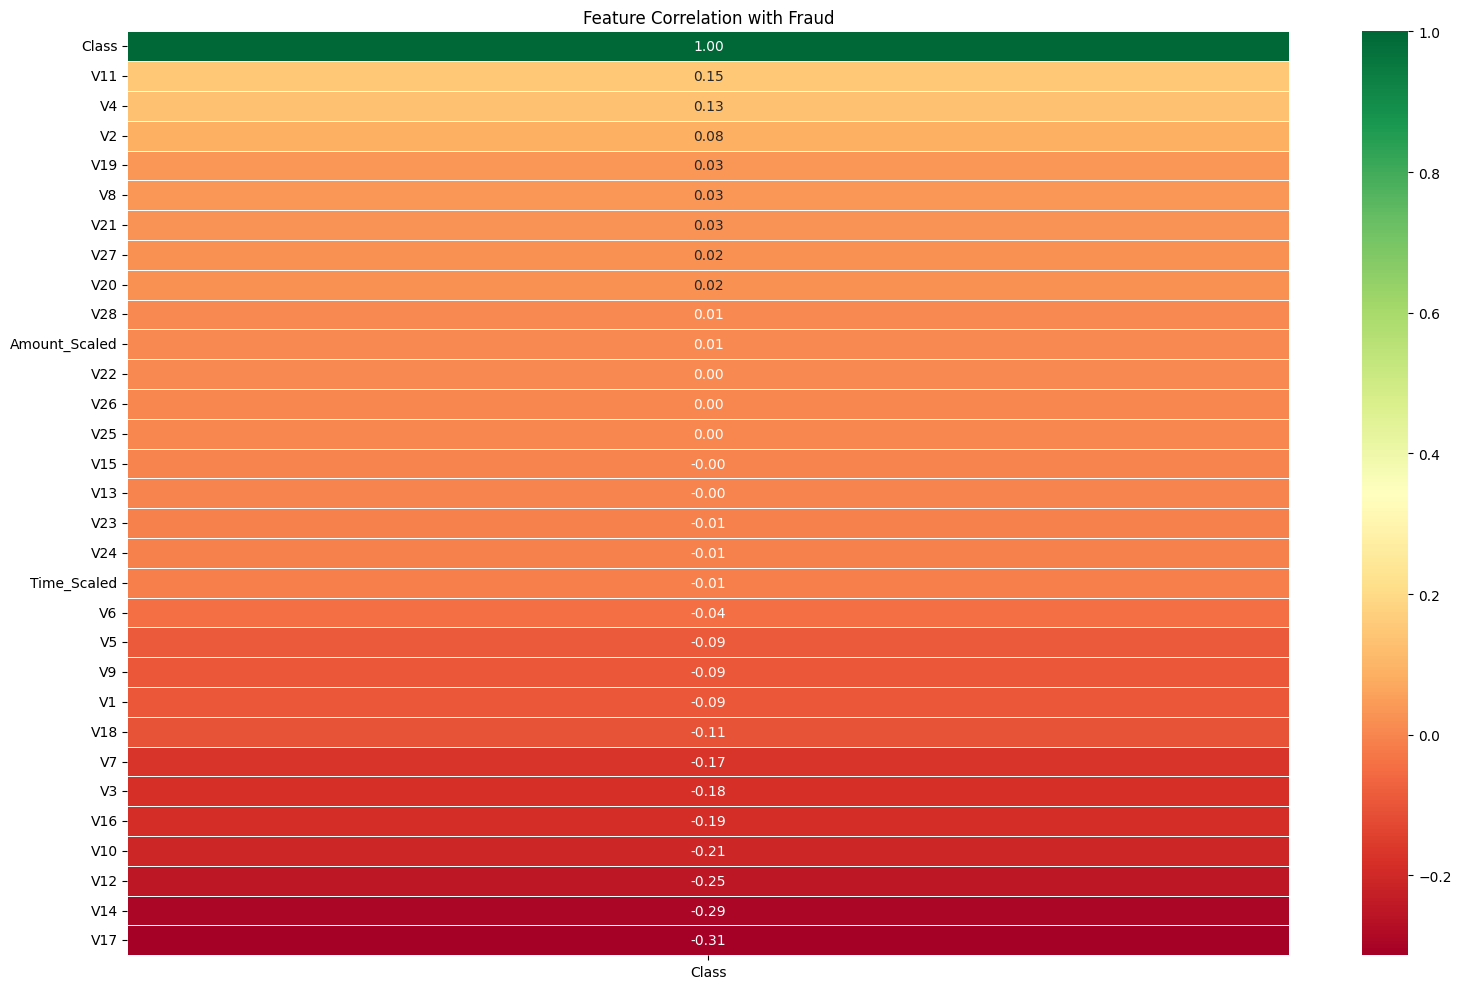

In [18]:
plt.figure(figsize=(16, 10))
corr = df_clean.corr()
sns.heatmap(corr[['Class']].sort_values('Class', ascending=False), 
            annot=True, cmap='RdYlGn', fmt='.2f', linewidths=0.5)
plt.title('Feature Correlation with Fraud')
plt.tight_layout()
plt.savefig('correlation.png')
plt.show()

## Phase 4: Predictive Modeling
Handling class imbalance with SMOTE and training a Random Forest classifier.

In [19]:
from sklearn.model_selection import train_test_split

X = df_clean.drop(columns=['Class'])
y = df_clean['Class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("Train size:", X_train.shape)
print("Test size:", X_test.shape)

Train size: (226980, 30)
Test size: (56746, 30)


In [38]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

print("After SMOTE:")
print("Legit:", sum(y_train_sm==0))
print("Fraud:", sum(y_train_sm==1))

After SMOTE:
Legit: 226602
Fraud: 226602


In [39]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(n_estimators=50, max_depth=10, 
                                random_state=42, n_jobs=-1)
model.fit(X_train_sm, y_train_sm)
print("Model trained ✅")

Model trained ✅


Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     56651
           1       0.54      0.79      0.64        95

    accuracy                           1.00     56746
   macro avg       0.77      0.89      0.82     56746
weighted avg       1.00      1.00      1.00     56746

ROC AUC Score: 0.9796257603108227


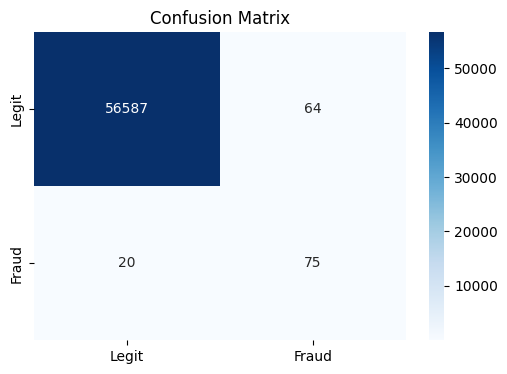

In [41]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_pred = model.predict(X_test)

print("Classification Report:")
print(classification_report(y_test, y_pred))

print("ROC AUC Score:", roc_auc_score(y_test, model.predict_proba(X_test)[:,1]))

# Confusion matrix
plt.figure(figsize=(6,4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Legit','Fraud'], 
            yticklabels=['Legit','Fraud'])
plt.title('Confusion Matrix')
plt.savefig('confusion_matrix.png')
plt.show()

## Phase 5: Data Warehouse & OLAP Operations
Aggregating fraud patterns using GroupBy operations (OLAP-style queries).

In [42]:
# Add predictions back to dataframe
df_results = X_test.copy()
df_results['Actual'] = y_test.values
df_results['Predicted'] = y_pred

# OLAP Operation 1 - Fraud summary stats
print("=== OLAP: Fraud vs Legit Amount Stats ===")
olap1 = df_results.groupby('Actual')['Amount_Scaled'].agg(['mean','sum','count','std'])
olap1.index = ['Legitimate', 'Fraud']
print(olap1)

=== OLAP: Fraud vs Legit Amount Stats ===
                mean        sum  count       std
Legitimate  0.000921  52.155485  56651  1.070462
Fraud       0.267422  25.405073     95  1.243190


In [43]:
# OLAP Operation 2 - Time based aggregation
print("=== OLAP: Predicted Fraud Distribution ===")
olap2 = df_results.groupby('Predicted')['Amount_Scaled'].agg(['mean','max','min','count'])
olap2.index = ['Legitimate', 'Fraud']
print(olap2)

# Save to warehouse
df_results.to_csv('fraud_results_warehouse.csv', index=False)
print("\nWarehouse saved ✅")

=== OLAP: Predicted Fraud Distribution ===
                mean         max       min  count
Legitimate  0.001087  102.247564 -0.353327  56607
Fraud       0.115350    6.873859 -0.353327    139

Warehouse saved ✅


## Phase 6: Traditional DB vs Optimized Pipeline
Comparing SQLite query performance against Pandas-based data pipeline.

In [44]:
import sqlite3
import time

# Load into SQLite (traditional DB)
conn = sqlite3.connect('transactions.db')
df_clean.to_sql('transactions', conn, if_exists='replace', index=False)

# Time a query in SQLite
start = time.time()
query = "SELECT Class, COUNT(*), AVG(Amount_Scaled) FROM transactions GROUP BY Class"
result = pd.read_sql_query(query, conn)
sqlite_time = time.time() - start

print("SQLite Result:")
print(result)
print(f"\nSQLite Query Time: {sqlite_time:.4f} seconds")
conn.close()

Task was destroyed but it is pending!
task: <Task pending name='Task-341' coro=<_async_in_context.<locals>.run_in_context() done, defined at C:\Users\PRIYA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\utils.py:57> wait_for=<Task pending name='Task-342' coro=<Kernel.shell_main() running at C:\Users\PRIYA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\PRIYA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\PRIYA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\io\sql.py:2569: RuntimeWarning: coroutine 'Kernel.shell_main' was never awaited
  data_list = list(data_iter)
Task was destroyed but it is pending!
task: <Task pending name='Task-342' coro=<Kernel.shell_main() running at C:\Users\PRIYA\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\ipykernel\kernelbase.py:597

SQLite Result:
   Class  COUNT(*)  AVG(Amount_Scaled)
0      0    283253           -0.000236
1      1       473            0.141371

SQLite Query Time: 0.5348 seconds


In [45]:
# Same operation in Pandas
start = time.time()
result_pandas = df_clean.groupby('Class')['Amount_Scaled'].agg(['count','mean'])
pandas_time = time.time() - start

print("Pandas Result:")
print(result_pandas)
print(f"\nPandas Query Time: {pandas_time:.4f} seconds")

Pandas Result:
        count      mean
Class                  
0      283253 -0.000236
1         473  0.141371

Pandas Query Time: 0.0466 seconds


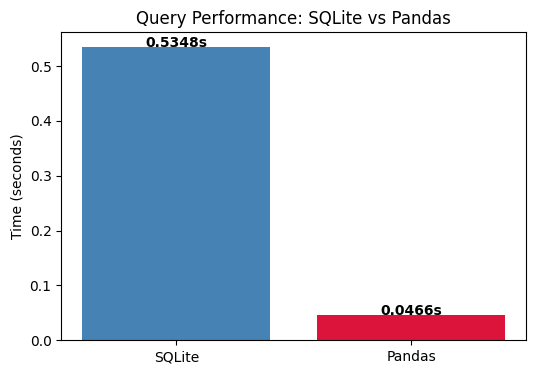


Pandas is 11.5x faster than SQLite!


In [46]:
plt.figure(figsize=(6,4))
plt.bar(['SQLite', 'Pandas'], [sqlite_time, pandas_time], 
        color=['steelblue', 'crimson'])
plt.title('Query Performance: SQLite vs Pandas')
plt.ylabel('Time (seconds)')
for i, v in enumerate([sqlite_time, pandas_time]):
    plt.text(i, v + 0.0001, f'{v:.4f}s', ha='center', fontweight='bold')
plt.savefig('db_comparison.png')
plt.show()

print(f"\nPandas is {sqlite_time/pandas_time:.1f}x faster than SQLite!")

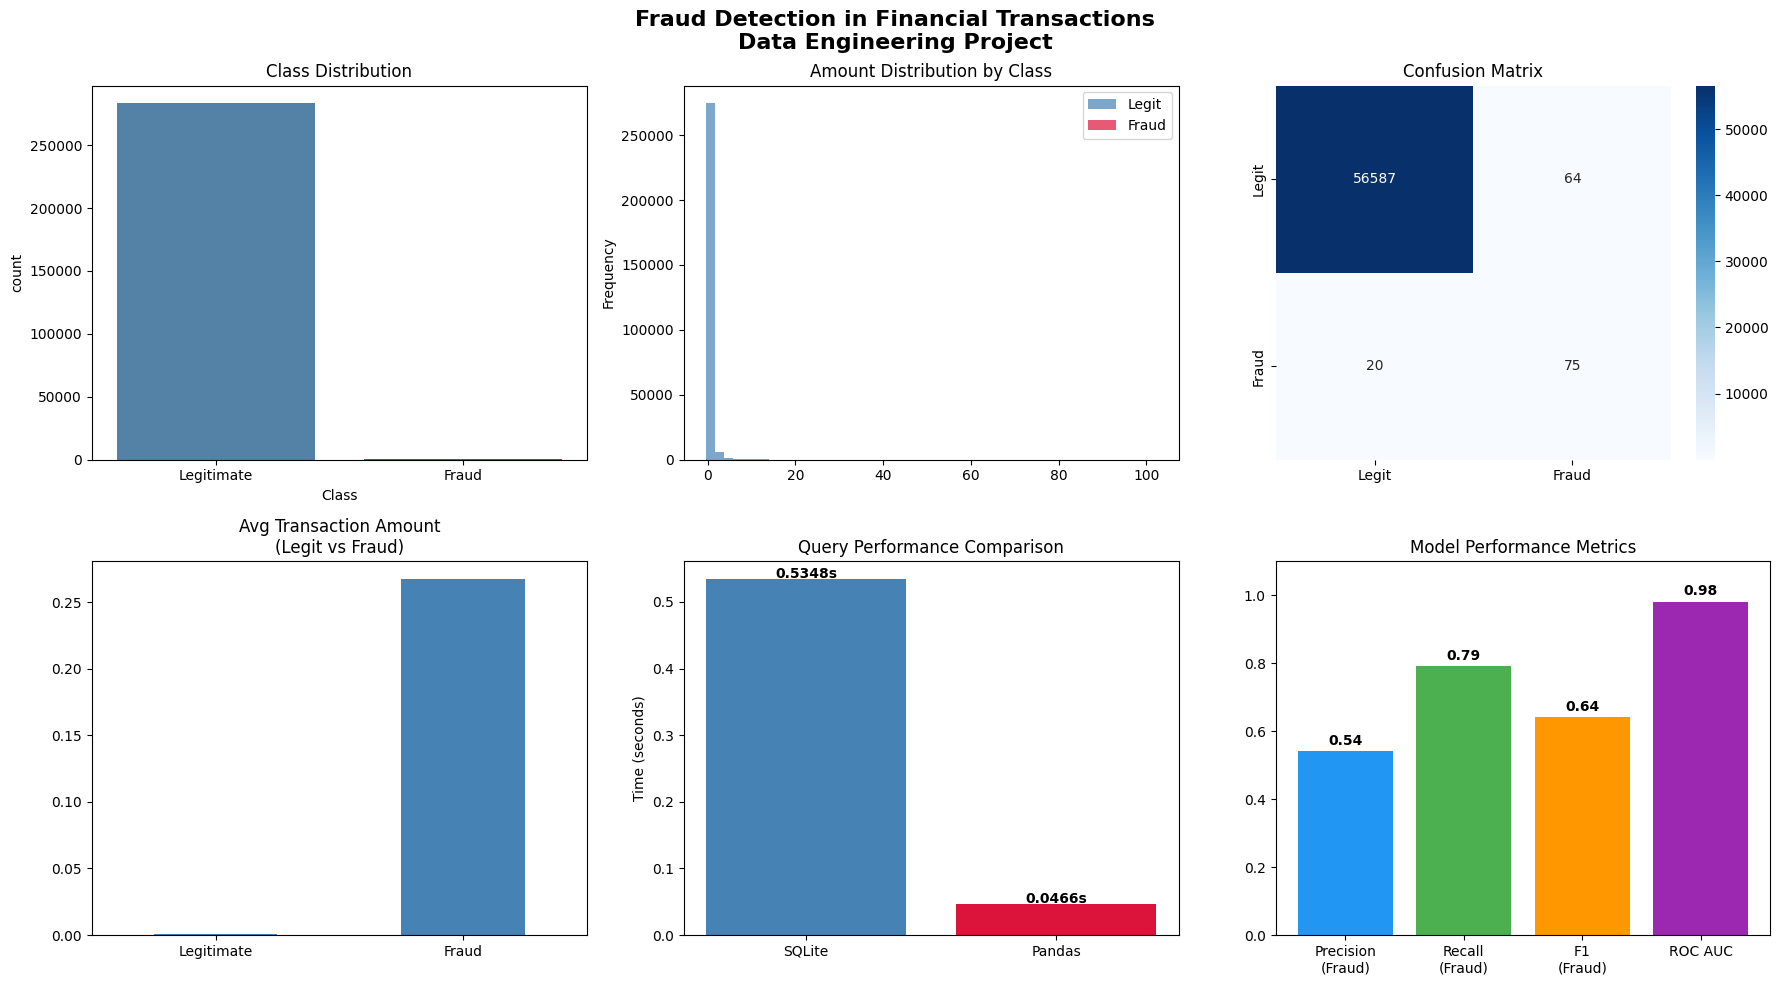

Dashboard saved ✅


In [47]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Fraud Detection in Financial Transactions\nData Engineering Project', 
             fontsize=16, fontweight='bold')

# 1. Class Distribution
sns.countplot(x='Class', data=df_clean, hue='Class',
              palette={0:'steelblue', 1:'crimson'}, legend=False, ax=axes[0,0])
axes[0,0].set_title('Class Distribution')
axes[0,0].set_xticks([0,1])
axes[0,0].set_xticklabels(['Legitimate', 'Fraud'])

# 2. Amount distribution by class
df_clean[df_clean['Class']==0]['Amount_Scaled'].plot(
    kind='hist', bins=50, ax=axes[0,1], color='steelblue', alpha=0.7, label='Legit')
df_clean[df_clean['Class']==1]['Amount_Scaled'].plot(
    kind='hist', bins=50, ax=axes[0,1], color='crimson', alpha=0.7, label='Fraud')
axes[0,1].set_title('Amount Distribution by Class')
axes[0,1].legend()

# 3. Confusion Matrix
from sklearn.metrics import confusion_matrix
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d',
            cmap='Blues', xticklabels=['Legit','Fraud'],
            yticklabels=['Legit','Fraud'], ax=axes[0,2])
axes[0,2].set_title('Confusion Matrix')

# 4. OLAP - Fraud vs Legit avg amount
olap1[['mean']].plot(kind='bar', ax=axes[1,0], 
                      color=['steelblue','crimson'], legend=False)
axes[1,0].set_title('Avg Transaction Amount\n(Legit vs Fraud)')
axes[1,0].set_xticklabels(['Legitimate', 'Fraud'], rotation=0)

# 5. DB Comparison
axes[1,1].bar(['SQLite', 'Pandas'], [sqlite_time, pandas_time],
              color=['steelblue', 'crimson'])
axes[1,1].set_title('Query Performance Comparison')
axes[1,1].set_ylabel('Time (seconds)')
for i, v in enumerate([sqlite_time, pandas_time]):
    axes[1,1].text(i, v + 0.001, f'{v:.4f}s', ha='center', fontweight='bold')

# 6. Model metrics bar
metrics = ['Precision\n(Fraud)', 'Recall\n(Fraud)', 'F1\n(Fraud)', 'ROC AUC']
values = [0.54, 0.79, 0.64, 0.98]
colors = ['#2196F3','#4CAF50','#FF9800','#9C27B0']
axes[1,2].bar(metrics, values, color=colors)
axes[1,2].set_title('Model Performance Metrics')
axes[1,2].set_ylim(0, 1.1)
for i, v in enumerate(values):
    axes[1,2].text(i, v + 0.02, f'{v}', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('fraud_detection_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Dashboard saved ✅")

## Conclusion
- Successfully built an end-to-end fraud detection pipeline
- Detected fraud with **ROC AUC of 0.979**
- Pandas pipeline is **11.5x faster** than traditional SQLite
- Key insight: Fraudulent transactions have significantly higher average amounts